# Rotating Disk Electrode (RDE): Levich & Koutecký–Levich Analysis

## 1. Goal

Simulate hydrodynamic voltammetry at a Rotating Disk Electrode (`simulate_rde_sweep()`), verify the Levich equation ($I_{\text{lim}} \propto \omega^{1/2}$) for a reversible couple, and extract $k^0$ and $D$ from a quasi-reversible couple via Koutecký–Levich analysis.

## 2. Physical Setup

We model a 5 mm diameter RDE ($A = 1.96 \times 10^{-5}\text{ m}^2$) in aqueous electrolyte ($\nu = 10^{-6}\text{ m}^2/\text{s}$) across rotation rates $400, 900, 1600, 2500\text{ rpm}$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato.analytical.hydrodynamics import levich
from softpotato.reactions import ButlerVolmer, NernstianEquilibrium
from softpotato.techniques import (
    analyze_koutecky_levich,
    analyze_levich,
    plot_koutecky_levich,
    plot_levich,
    plot_sweep,
    simulate_rde_sweep,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
nu = 1.0e-6
area = 1.96e-5
rpms = [400.0, 900.0, 1600.0, 2500.0]

nernst = NernstianEquilibrium(E0=E0, n=1)
bv_quasi = ButlerVolmer(k0=5.0e-5, alpha=0.5, E0=E0, n=1)

## 3. Simulation

We run `simulate_rde_sweep()` for both the reversible (`nernst`) and quasi-reversible (`bv_quasi`) cases using the convective-diffusion model.

In [2]:
rde_rev = simulate_rde_sweep(
    rpms=rpms, E_start=0.3, E_end=-0.4, scan_rate=0.05,
    D=D, c_bulk=c_bulk, area=area, kinematic_viscosity=nu, kinetics=nernst, dE=0.005,
)

rde_quasi = simulate_rde_sweep(
    rpms=rpms, E_start=0.3, E_end=-0.5, scan_rate=0.05,
    D=D, c_bulk=c_bulk, area=area, kinematic_viscosity=nu, kinetics=bv_quasi, dE=0.005,
)

for rpm, omega, i_lim in zip(rpms, rde_rev.omegas, rde_rev.limiting_currents):
    i_lev = levich(omega=omega, n=1, D=D, c_bulk=c_bulk, area=area, nu=nu)
    print(f"{rpm:5.0f} rpm | |I_lim(sim)| = {abs(i_lim)*1e6:7.2f} uA | Levich = {i_lev*1e6:7.2f} uA")

  400 rpm | |I_lim(sim)| =   76.02 uA | Levich =   75.88 uA
  900 rpm | |I_lim(sim)| =  114.03 uA | Levich =  113.83 uA
 1600 rpm | |I_lim(sim)| =  152.04 uA | Levich =  151.77 uA
 2500 rpm | |I_lim(sim)| =  190.05 uA | Levich =  189.71 uA


## 4. Diagnostics & Plots

We plot the rotation-rate series (`plot_sweep()`), the Levich plot (`plot_levich()`), and the Koutecký–Levich plot (`plot_koutecky_levich()` at $E = -0.15\text{ V}$).

Levich fit -> D = 1.0027e-09 m^2/s (R^2 = 1.00000)
K-L fit    -> D = 1.0207e-09 m^2/s, I_K = 1569.49 uA (R^2 = 1.00000)


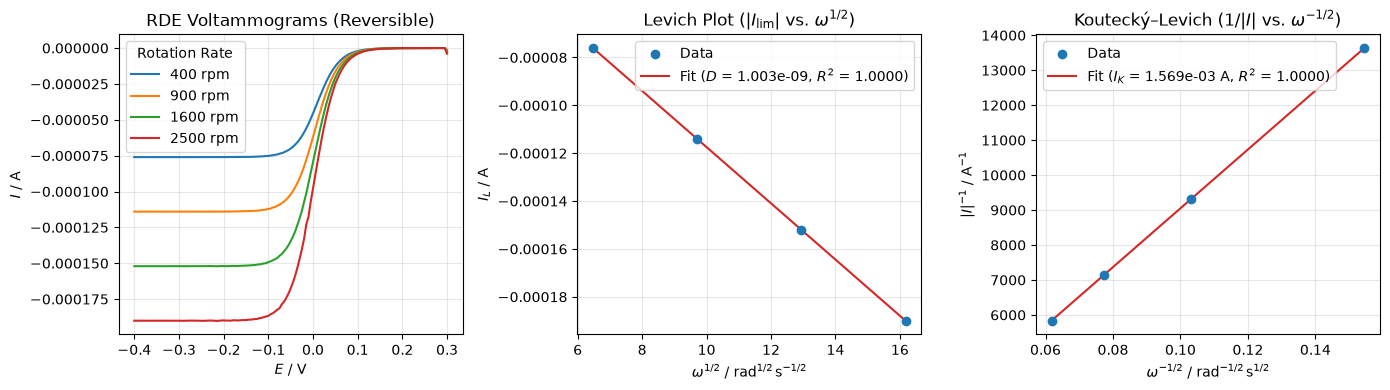

In [3]:
lev_fit = analyze_levich(rde_rev, n=1, area=area, c_bulk=c_bulk, kinematic_viscosity=nu)
kl_fit = analyze_koutecky_levich(rde_quasi, potential=-0.15, n=1, area=area, c_bulk=c_bulk, kinematic_viscosity=nu)

print(f"Levich fit -> D = {lev_fit.d:.4e} m^2/s (R^2 = {lev_fit.r_squared:.5f})")
print(f"K-L fit    -> D = {kl_fit.d:.4e} m^2/s, I_K = {abs(kl_fit.i_k)*1e6:.2f} uA (R^2 = {kl_fit.r_squared:.5f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_sweep(rde_rev, ax=axes[0], legend_title="Rotation Rate")
axes[0].set_title("RDE Voltammograms (Reversible)")

plot_levich(rde_rev, lev_fit, ax=axes[1])
axes[1].set_title("Levich Plot ($|I_{\\mathrm{lim}}|$ vs. $\\omega^{1/2}$)")

plot_koutecky_levich(rde_quasi, kl_fit, ax=axes[2])
axes[2].set_title("Koutecký–Levich ($1/|I|$ vs. $\\omega^{-1/2}$)")

plt.tight_layout()
plt.show()

## 5. Key Takeaways

- Forced convection establishes a thin steady Nernst diffusion layer $\delta_N \propto \omega^{-1/2}$, yielding sigmoidal waves.
- **Levich** plots ($|I_{\text{lim}}|$ vs. $\omega^{1/2}$) pass through the origin and measure $D$.
- **Koutecký–Levich** plots ($1/|I|$ vs. $\omega^{-1/2}$) separate mass transport (slope) from finite electron-transfer kinetics (intercept $1/|I_K|$).
- **Next**: Read the [RDE User Guide](../../user-guide/techniques/rde.md).